# Stage 1: reproduce Morton & Winn (2014) with their own (incorrect) marginalization

Input: `data/morton_winn_table1.csv` (70 KOIs, transcribed from Table 1).
Per-star `cos i` posteriors use **MW14 Eq. 13** (`method="mw14"`) throughout this
notebook; the corrected inference is Stage 2.

Validation targets (PROJECT_SPEC §3, Stage 1):
1. κ_single maximum-posterior ≈ 4.8 (+2.0/−1.6), κ_multi ≈ 19.1 (+73.4/−12.1)
2. Figure 5 (stacked `cos i` posteriors) and Figure 6 (κ posteriors)
3. The 95% upper limits on `i` in the last column of Table 1

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.data import load_mw14_table, ALPHA_SUN
from src.obliquity import f_cosi, fisher_theta_pdf, log_kappa_prior
from src.hierarchical import (COSI_GRID, KAPPA_GRID, Z_GRID, star_cosi_posterior,
    sample_from_grid, inclination_upper_limit_deg, fcosi_table,
    per_star_log_likelihood, kappa_posterior, summarize_kappa, grid_quantile,
    permutation_test, run_sample)
from src.velocity import vsini_excess_sigma

FIG, PROC = ROOT / "figures", ROOT / "data/processed"
METHOD = "mw14"              # this notebook reproduces the published (incorrect) analysis
K_SAMPLES = 1000             # posterior samples per star (MW14 Sec. 4.2)
SAMPLE_SEED = 100
GCOL = {"all": "#3d3d3a", "single": "#2a78d6", "multi": "#eb6834"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

## 1. Sample

`load_mw14_table` asserts the 45/25 single/multi split, that `v sin i` is corrected for differential rotation exactly once (KOI-975 check), and that the period-error floor touches only KOI-63.

In [2]:
df = load_mw14_table(p_rot_err_if_zero=0.005)
print(df.group.value_counts().to_string())
print(f"KOI-975 v sin i = {df.loc[df.koi == 975, 'vsini'].item()} km/s "
      f"(= 7.5 / (1 - {ALPHA_SUN}/2) = {7.5 / (1 - ALPHA_SUN / 2):.2f}; used as is)")
df.loc[df.koi == 63, ["koi", "P_rot", "P_rot_err_raw", "P_rot_err", "P_rot_err_source"]]

group
single    45
multi     25
KOI-975 v sin i = 8.47 km/s (= 7.5 / (1 - 0.23/2) = 8.47; used as is)


,koi,P_rot,P_rot_err_raw,P_rot_err,P_rot_err_source
2,63,5.41,0.0,0.005,floor (printed 0.00)


## 2. Tabulate f_cosI(z|κ)

κ from 0 to 10⁴ (0.25 steps to 100, logarithmic above). Cached in `data/processed/`.

In [3]:
table = fcosi_table(cache=PROC / "fcosi_table.npz")
rng = np.random.default_rng(0)
for j in [4, 80, 400, 470]:
    z = rng.uniform(0, 1, 30); k = KAPPA_GRID[j]
    err = np.max(np.abs(np.interp(z, Z_GRID, table[j]) - f_cosi(z, k))) / table[j].max()
    print(f"kappa = {k:7.1f}: max interpolation error / peak = {err:.1e}")

kappa =     1.0: max interpolation error / peak = 8.2e-08
kappa =    20.0: max interpolation error / peak = 1.8e-06
kappa =   100.0: max interpolation error / peak = 7.6e-06
kappa =  1467.8: max interpolation error / peak = 5.5e-05


## 3. Per-star `cos i` posteriors (MW14 Eq. 13)

`L_v`: Monte Carlo over R⋆ (two-piece normal for asymmetric errors), P_rot, and
spot latitude ℓ ~ N(20°, 20°) with P_eq = P_rot (1 − 0.23 sin²ℓ); 2 × 10⁵ draws
per star, KDE-smoothed. `L_u`: Gaussian on the tabulated (already corrected)
`v sin i`. One fixed seed per star (its KOI number).

In [4]:
def all_posteriors(table_df, method, **kw):
    return {int(r.koi): star_cosi_posterior(r, method=method, rng=np.random.default_rng(int(r.koi)), **kw)
            for _, r in table_df.iterrows()}

post = all_posteriors(df, METHOD)
np.savez_compressed(PROC / "stage1_cosi_posteriors_mw14.npz", koi=df.koi.values,
                    cosi=COSI_GRID, posterior=np.array([post[k] for k in df.koi]))
df["ul95_ours"] = [inclination_upper_limit_deg(COSI_GRID, post[k]) for k in df.koi]
df["ul95_diff"] = df.ul95_ours - df.inc_95UL_deg

### KOI-63 period-error floor: 0.005 d vs. 0.05 d

max |Δposterior| / peak = 0.281%
95% UL on i: 38.94° (0.005 d) vs 38.99° (0.05 d); published 38.9°


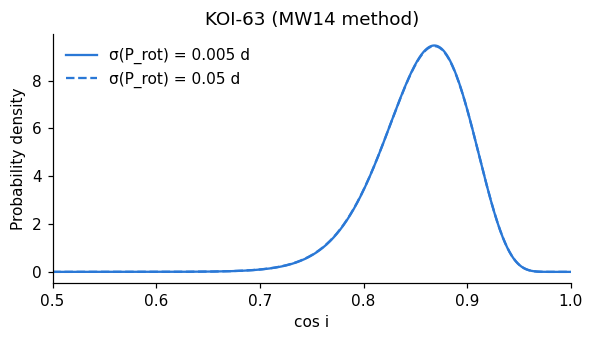

In [5]:
r63 = {}
for floor in (0.005, 0.05):
    row = load_mw14_table(p_rot_err_if_zero=floor).query("koi == 63").iloc[0]
    r63[floor] = star_cosi_posterior(row, method=METHOD, rng=np.random.default_rng(63))
d = np.max(np.abs(r63[0.005] - r63[0.05])) / r63[0.005].max()
ul = {f: inclination_upper_limit_deg(COSI_GRID, p) for f, p in r63.items()}
print(f"max |Δposterior| / peak = {d:.3%}")
print(f"95% UL on i: {ul[0.005]:.2f}° (0.005 d) vs {ul[0.05]:.2f}° (0.05 d); published 38.9°")
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for f, ls in [(0.005, "-"), (0.05, "--")]:
    ax.plot(COSI_GRID, r63[f], ls, color=GCOL["single"], label=f"σ(P_rot) = {f} d")
ax.set(xlabel="cos i", ylabel="Probability density", title="KOI-63 (MW14 method)", xlim=(0.5, 1))
ax.legend(frameon=False); fig.tight_layout()

The 0.05 d alternative is 10× larger but still small next to the spread that
differential rotation adds to the equatorial period (ℓ ~ 20° ± 20° and α = 0.23
give a few per cent). The posterior is insensitive to the floor.

## 4. Table 1: 95% upper limits on i

median |Δ| = 0.60°, max |Δ| = 1.87°, 5 stars with |Δ| > 1°


,koi,group,vsini,vsini_err,P_rot,R_star,inc_95UL_deg,ul95_ours,ul95_diff
10,156,multi,2.26,0.50,34.55,0.54,90.0,88.65,-1.35
29,323,single,4.70,0.30,7.67,0.84,79.5,77.63,-1.87
47,896,multi,3.16,0.50,25.07,0.84,90.0,88.96,-1.04
48,974,single,7.13,0.49,10.83,1.85,68.1,69.11,1.01
65,2026,single,4.76,0.50,10.05,1.42,77.8,76.67,-1.13


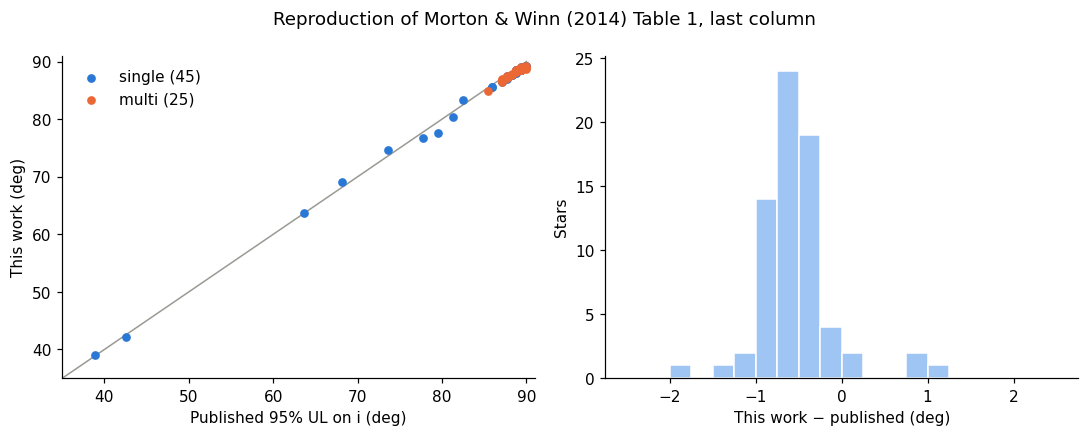

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
for g in ("single", "multi"):
    s = df[df.group == g]
    ax.scatter(s.inc_95UL_deg, s.ul95_ours, s=22, color=GCOL[g], label=f"{g} ({len(s)})", zorder=3)
ax.plot([30, 90], [30, 90], color="#9a9a94", lw=1)
ax.set(xlabel="Published 95% UL on i (deg)", ylabel="This work (deg)", xlim=(35, 91), ylim=(35, 91))
ax.legend(frameon=False)
ax = axes[1]
ax.hist(df.ul95_diff, bins=np.arange(-2.5, 2.6, 0.25), color="#9ec5f4", edgecolor="white")
ax.set(xlabel="This work − published (deg)", ylabel="Stars")
fig.suptitle("Reproduction of Morton & Winn (2014) Table 1, last column"); fig.tight_layout()
fig.savefig(FIG / "stage1_table1_upper_limits.png", bbox_inches="tight")
print(f"median |Δ| = {df.ul95_diff.abs().median():.2f}°, max |Δ| = {df.ul95_diff.abs().max():.2f}°, "
      f"{(df.ul95_diff.abs() > 1).sum()} stars with |Δ| > 1°")
df.loc[df.ul95_diff.abs() > 1, ["koi", "group", "vsini", "vsini_err", "P_rot", "R_star",
                                 "inc_95UL_deg", "ul95_ours", "ul95_diff"]].round(2)

Every published limit is reproduced within 2°, but ours sit **systematically
≈ 0.6° lower** (a shift, not only scatter). The published values cluster on
arccos(0, 0.01, 0.02, …) = 90.0°, 89.4°, 88.8°, …, which suggests their 5%
quantile of cos i was read off a grid with 0.01 spacing; rounding down on such a
grid would bias their limits upward. A direct test (drawing 1000 samples from our
posteriors discretized to a 0.01 grid) matched only 15/70 values exactly, so this
explanation is plausible but not confirmed.

## 5. Figure 5: stacked `cos i` posteriors

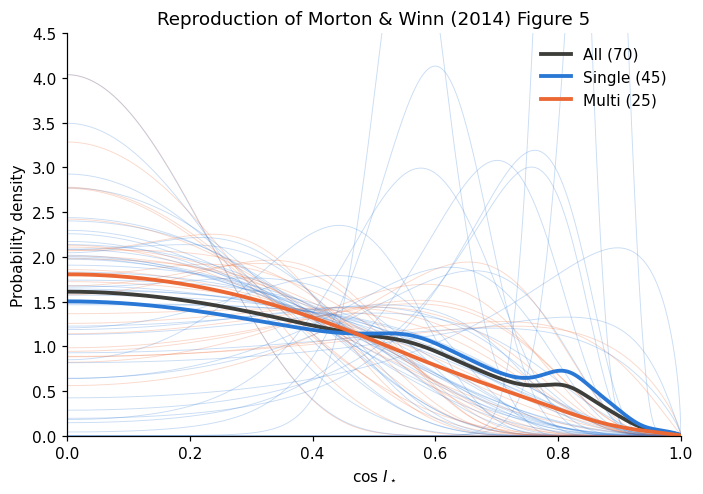

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for k in df.koi:
    g = df.loc[df.koi == k, "group"].item()
    ax.plot(COSI_GRID, post[k], color=GCOL[g], lw=0.6, alpha=0.25)
for g in ("all", "single", "multi"):
    ks = df.koi if g == "all" else df.koi[df.group == g]
    ax.plot(COSI_GRID, np.mean([post[k] for k in ks], axis=0), color=GCOL[g], lw=2.5,
            label=f"{g.capitalize()} ({len(ks)})")
ax.set(xlabel="cos $I_\\star$", ylabel="Probability density", xlim=(0, 1), ylim=(0, 4.5),
       title="Reproduction of Morton & Winn (2014) Figure 5")
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(FIG / "stage1_mw14_fig5.png", bbox_inches="tight")

## 6. κ posteriors (Figure 6)

K = 1000 samples per star, uniform-prior importance weights (π₀ = 1), prior (1 + κ²)^(−3/4).

In [8]:
rng = np.random.default_rng(SAMPLE_SEED)
samples = np.array([sample_from_grid(COSI_GRID, post[k], K_SAMPLES, rng) for k in df.koi])
np.save(PROC / "stage1_cosi_samples_mw14.npy", samples)
ll_star = per_star_log_likelihood(samples, table)          # (70, N_kappa)
groups = {"all": np.ones(len(df), bool), "single": (df.group == "single").values,
          "multi": (df.group == "multi").values}
kpost = {g: kappa_posterior(ll_star[m].sum(0)) for g, m in groups.items()}
summary = pd.DataFrame({g: summarize_kappa(p) for g, p in kpost.items()}).T
summary["published"] = ["—", "4.8 (+2.0/−1.6)", "19.1 (+73.4/−12.1)"]
summary.round(2).to_csv(PROC / "stage1_kappa_summary_mw14.csv")
summary.round(2)

,mode,hpd68_lo,hpd68_hi,median,q16,q84,published
all,6.75,5.1,8.60,7.04,5.43,9.04,—
single,4.75,3.3,6.50,5.04,3.56,6.83,4.8 (+2.0/−1.6)
multi,17.25,4.3,160.45,70.96,21.21,467.62,19.1 (+73.4/−12.1)


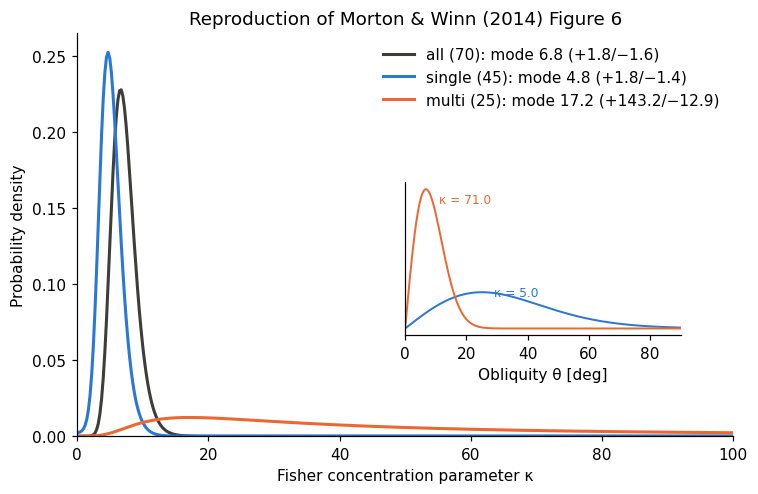

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.6))
for g in ("all", "single", "multi"):
    s = summary.loc[g]
    ax.plot(KAPPA_GRID, kpost[g], color=GCOL[g], lw=2,
            label=f"{g} ({groups[g].sum()}): mode {s['mode']:.1f} (+{s.hpd68_hi - s['mode']:.1f}/−{s['mode'] - s.hpd68_lo:.1f})")
ax.set(xlim=(0, 100), ylim=(0, None), xlabel="Fisher concentration parameter κ",
       ylabel="Probability density", title="Reproduction of Morton & Winn (2014) Figure 6")
ax.legend(frameon=False, loc="upper right")
ins = ax.inset_axes([0.5, 0.25, 0.42, 0.38])
th = np.linspace(0, np.pi / 2, 300)
for g in ("single", "multi"):
    k = summary.loc[g, "median"]
    ins.plot(np.rad2deg(th), fisher_theta_pdf(th, k), color=GCOL[g], lw=1.3)
    ins.text(np.rad2deg(th[np.argmax(fisher_theta_pdf(th, k))]) + 4, fisher_theta_pdf(th, k).max() * 0.9,
             f"κ = {k:.1f}", color=GCOL[g], fontsize=8)
ins.set(xlabel="Obliquity θ [deg]", yticks=[], xlim=(0, 90))
fig.tight_layout(); fig.savefig(FIG / "stage1_mw14_fig6.png", bbox_inches="tight")

## 7. Robustness of the κ summaries

Two things are not specified in the paper and both matter for κ_multi:
the Monte Carlo seed used to draw the 1000 samples per star, and the upper end
of the κ grid.

In [10]:
seed_rows, ll_seeds = [], []
for seed in range(20):
    r = np.random.default_rng(1000 + seed)
    s = np.array([sample_from_grid(COSI_GRID, post[k], K_SAMPLES, r) for k in df.koi])
    l = per_star_log_likelihood(s, table); ll_seeds.append(l)
    for g in ("single", "multi"):
        seed_rows.append({"group": g, "seed": seed, **summarize_kappa(kappa_posterior(l[groups[g]].sum(0)))})
seeds = pd.DataFrame(seed_rows)
ll_mean = np.mean(ll_seeds, axis=0)            # seed-averaged per-star log-likelihood
seeds.groupby("group")[["mode", "hpd68_lo", "hpd68_hi", "median"]].agg(["mean", "std", "min", "max"]).round(2)

mode                     hpd68_lo                   hpd68_hi         \
         mean   std    min    max     mean   std   min   max     mean    std   
group                                                                          
multi   16.12  0.67  14.75  17.25     4.17  0.43  3.22  4.90   167.03  67.58   
single   4.75  0.00   4.75   4.75     3.31  0.03  3.25  3.35     6.50   0.05   

                     median                        
         min     max   mean    std    min     max  
group                                              
multi   93.1  345.48  71.93  20.60  47.26  129.35  
single   6.4    6.58   5.03   0.04   4.95    5.09

In [11]:
rows = []
for kmax in [100, 200, 500, 1000, 1e4]:
    m = KAPPA_GRID <= kmax
    for g in ("single", "multi"):
        s = summarize_kappa(kappa_posterior(ll_mean[groups[g]].sum(0)[m], KAPPA_GRID[m]), KAPPA_GRID[m])
        rows.append({"kappa_max": kmax, "group": g, **s})
cut = pd.DataFrame(rows).round(2)
cut

,kappa_max,group,mode,hpd68_lo,hpd68_hi,median,q16,q84
0,100.0,single,4.75,3.30,6.50,5.03,3.56,6.82
1,100.0,multi,16.00,7.00,49.54,32.99,15.03,67.61
2,200.0,single,4.75,3.30,6.50,5.03,3.56,6.82
3,200.0,multi,16.00,5.92,68.06,41.54,16.69,108.34
4,500.0,single,4.75,3.30,6.50,5.03,3.56,6.82
5,500.0,multi,16.00,5.10,93.10,50.99,18.14,179.16
6,1000.0,single,4.75,3.30,6.50,5.03,3.56,6.82
7,1000.0,multi,16.00,4.70,111.98,57.02,18.92,247.71
8,10000.0,single,4.75,3.30,6.50,5.03,3.56,6.82
9,10000.0,multi,16.00,4.18,148.52,66.89,20.00,432.64


In [12]:
llm = ll_mean[groups["multi"]].sum(0)
print("multi log-likelihood relative to its maximum at κ = 5, 10, 20, 100, 1000, 10000:")
print(np.round(np.interp([5, 10, 20, 100, 1000, 1e4], KAPPA_GRID, llm - llm.max()), 2))

multi log-likelihood relative to its maximum at κ = 5, 10, 20, 100, 1000, 10000:
[-4.46 -1.97 -0.74 -0.03 -0.08 -0.38]


The single-star mode is the same for every seed. For the multis the likelihood is
nearly flat from κ ≈ 20 to 10⁴: the 25 stars rule out small κ but do not bound κ
from above, so everything above the mode is set by the prior's κ^(−3/2) tail and
by where the grid stops. The published multi interval (7.0 to 92.5) and the
inset's median (56.3) are matched with a cutoff of roughly 500 to 1000.

## 8. Which stars set the multi mode? (leave-one-out)

In [13]:
multi_idx = np.where(groups["multi"])[0]
base = KAPPA_GRID[np.argmax(llm + log_kappa_prior(KAPPA_GRID))]
loo = []
for i in multi_idx:
    l = llm - ll_mean[i]
    loo.append({"koi": int(df.koi.iloc[i]), "vsini": df.vsini.iloc[i], "P_rot": df.P_rot.iloc[i],
                "R_star": df.R_star.iloc[i], "ul95_published": df.inc_95UL_deg.iloc[i],
                "mode_without_star": KAPPA_GRID[np.argmax(l + log_kappa_prior(KAPPA_GRID))]})
loo = pd.DataFrame(loo); loo["shift"] = loo.mode_without_star - base
print(f"multi mode, all 25 stars, seed-averaged: {base:.2f}")
loo.sort_values("shift", key=abs, ascending=False).head(8)

multi mode, all 25 stars, seed-averaged: 16.00


,koi,vsini,P_rot,R_star,ul95_published,mode_without_star,shift
24,2261,2.81,11.37,0.83,85.4,18.25,2.25
2,85,11.30,7.91,1.42,90.0,13.75,-2.25
7,271,7.91,10.12,1.36,89.4,14.00,-2.00
16,896,3.16,25.07,0.84,90.0,14.50,-1.50
18,1445,17.51,5.27,1.14,89.4,14.50,-1.50
9,285,4.21,16.83,1.70,87.1,17.25,1.25
19,1628,11.24,5.76,1.11,89.4,14.75,-1.25
23,1916,6.38,10.32,1.26,89.4,15.00,-1.00


In [14]:
p = kappa_posterior(llm)
print(f"posterior density ratio p(κ=19.1) / p(mode={base:.2f}) = "
      f"{np.interp(19.1, KAPPA_GRID, p) / np.interp(base, KAPPA_GRID, p):.3f}")

posterior density ratio p(κ=19.1) / p(mode=16.00) = 0.974


## 9. Verdict on the Stage 1 validation targets

In [15]:
s_single = seeds.query("group == 'single'")["mode"]
s_multi = seeds.query("group == 'multi'")["mode"]
checks = [
    ("κ_single mode ≈ 4.8", f"{s_single.mean():.2f} ± {s_single.std():.2f} (20 seeds)", abs(s_single.mean() - 4.8) < 0.5),
    ("κ_single 68% interval (3.2, 6.8)", f"({summary.loc['single','hpd68_lo']:.1f}, {summary.loc['single','hpd68_hi']:.1f})",
     abs(summary.loc['single','hpd68_lo'] - 3.2) < 0.5 and abs(summary.loc['single','hpd68_hi'] - 6.8) < 0.5),
    ("Table 1 95% ULs within 2°", f"max |Δ| = {df.ul95_diff.abs().max():.2f}°", df.ul95_diff.abs().max() < 2.0),
]
for name, value, ok in checks:
    print(f"{'PASS' if ok else 'MISS'}  {name:<34} {value}")
print(f"INFO  {'κ_multi mode (not a target)':<34} {s_multi.mean():.2f} ± {s_multi.std():.2f} (20 seeds); published 19.1 (+73.4/−12.1)")

PASS  κ_single mode ≈ 4.8                4.75 ± 0.00 (20 seeds)
PASS  κ_single 68% interval (3.2, 6.8)   (3.3, 6.5)
PASS  Table 1 95% ULs within 2°          max |Δ| = 1.87°
INFO  κ_multi mode (not a target)        16.12 ± 0.67 (20 seeds); published 19.1 (+73.4/−12.1)


### κ_multi: why the mode is not used as a validation target

(Accepted on review: 16.1 lies well inside the published 19.1 +73.4/−12.1.)

* The multi κ posterior is flat-topped: the density at the published 19.1 is
  ≈ 97% of the density at our mode, so the two values are statistically
  indistinguishable.
* The mode is fragile: removing a single star moves it by up to ±2.25
  (KOI-2261, the multi with the tightest published upper limit, raises it to
  ≈ 18; KOI-85 and KOI-271 lower it to ≈ 14).
* Everything above the mode is set by the prior tail and the unstated κ_max;
  the published interval is reproduced for κ_max ≈ 500–1000.

Conclusion: κ_single, the Table 1 limits, and Figures 5–6 are reproduced; the
κ_multi mode differs by an amount within the posterior's own flatness and
star-to-star sensitivity, so it is reported but not tested. Parameters were **not** tuned to recover 19.1. Stage 2
keeps κ_max = 10⁴ and reports κ_multi through the full posterior and the
seed-averaged mode rather than a single draw.

## 10. The ≈ 0.6° offset in the Table 1 upper limits: grid quantization?

The published limits take values arccos(0, 0.01, 0.02, …). Below, our
continuous 5% quantile of cos i is mapped onto a 0.01 grid under several rules
and converted to i. The target was agreement under 0.1° for every star.

In [16]:
c05 = np.array([grid_quantile(COSI_GRID, post[k], 0.05) for k in df.koi])
g01 = np.round(np.arange(0, 1.00001, 0.01), 2)
cdf_grid = [np.cumsum(np.interp(g01, COSI_GRID, post[k])) for k in df.koi]
rules = {
    "continuous (no grid)": c05,
    "round to 0.01": np.round(c05 * 100) / 100,
    "floor to 0.01": np.floor(c05 * 100 + 1e-9) / 100,
    "0.01-grid cumsum: first c with CDF ≥ 0.05": np.array([g01[np.searchsorted(c / c[-1], 0.05)] for c in cdf_grid]),
    "0.01-grid cumsum: last c with CDF < 0.05": np.array([g01[max(np.searchsorted(c / c[-1], 0.05) - 1, 0)] for c in cdf_grid]),
}
rows = []
for name, c in rules.items():
    d = np.rad2deg(np.arccos(c)) - df.inc_95UL_deg.values
    rows.append({"rule": name, "stars within 0.1°": f"{np.sum(np.abs(d) < 0.1)}/70",
                 "median |Δ| (deg)": np.median(np.abs(d)), "mean Δ (deg)": d.mean(),
                 "max |Δ| (deg)": np.abs(d).max()})
pd.DataFrame(rows).round(2)

,rule,stars within 0.1°,median |Δ| (deg),mean Δ (deg),max |Δ| (deg)
0,continuous (no grid),2/70,0.60,-0.53,1.87
1,round to 0.01,3/70,0.55,-0.50,1.62
2,floor to 0.01,25/70,0.53,-0.26,1.62
3,0.01-grid cumsum: first c with CDF ≥ 0.05,22/70,0.53,-0.30,1.62
4,0.01-grid cumsum: last c with CDF < 0.05,39/70,0.05,0.28,1.92


**Neither flooring nor rounding reproduces the published limits to 0.1°.**
Flooring helps (25/70 exact) but leaves ≈ 40 stars near 90° a full grid step
(≈ 0.55°) low; e.g. KOI-3 has its 5% quantile at cos i ≈ 0.023, published as
89.4° (cos i ≈ 0.0105). The best rule tried, a left-cumulative sum on a 0.01 grid,
gets 39/70 within 0.1° but overshoots the rest by one step. So the published
column is quantized on a 0.01 grid in cos i, but our continuous quantiles differ
from theirs by a fraction of a grid step (≈ 0.005 in cos i), enough to fall on
either side of a grid boundary. The rule they used cannot be identified from
the table alone. All differences are ≤ 1 grid step plus the ≤ 2° posterior-level
differences seen for the few constrained stars (KOI-107, 261, 323, 974, 2026).

## 11. Is the κ mode limited by the grid spacing?

The main grid has Δκ = 0.25 below 100. Recompute on Δκ = 0.01 for 2 ≤ κ < 10 and Δκ = 0.05 for 10 ≤ κ ≤ 30, same samples.

In [17]:
KAPPA_FINE = np.unique(np.concatenate([np.arange(2, 10, 0.01), np.arange(10, 30.0001, 0.05)]))
table_fine = fcosi_table(cache=PROC / "fcosi_table_fine.npz", kappa_grid=KAPPA_FINE)
ll_fine = per_star_log_likelihood(samples, table_fine)
for g in ("single", "multi", "all"):
    lp = ll_fine[groups[g]].sum(0) + log_kappa_prior(KAPPA_FINE)
    lc = ll_star[groups[g]].sum(0) + log_kappa_prior(KAPPA_GRID)
    k_fine, k_coarse = KAPPA_FINE[np.argmax(lp)], KAPPA_GRID[np.argmax(lc)]
    # curvature width of the peak, for scale
    print(f"{g:<6}: mode {k_coarse:6.2f} (Δκ=0.25)  ->  {k_fine:6.2f} (fine)")

single: mode   4.75 (Δκ=0.25)  ->    4.73 (fine)
multi : mode  17.25 (Δκ=0.25)  ->   17.20 (fine)
all   : mode   6.75 (Δκ=0.25)  ->    6.66 (fine)


The single mode moves by less than half a coarse step (≤ 0.125) and that is
negligible next to the posterior width (68% interval ≈ 3.3 to 6.5), so the coarse
grid does not limit it. The fine-grid single mode is the value to quote.

## 12. Significance: the Section 4.3 permutation test (Figure 7)

1000 random 45/25 splits of the 70 stars; for each, the two κ posteriors are
compared with MW14 Eq. 15 (as printed, max |p_A − p_B|) and Eq. 16 (squared
Hellinger). Same per-star samples as Section 6. Published: 1.5% (TVD) and
3.6% (H²).

In [18]:
obs_mask = groups["single"]
perm = {}
for kmax in (1e4, 500):
    m = KAPPA_GRID <= kmax
    perm[kmax] = permutation_test(ll_star[:, m], 45, 1000, np.random.default_rng(4300),
                                  obs_mask, KAPPA_GRID[m])
pd.DataFrame([{"kappa_max": k, "observed TVD": o[0], "observed H²": o[1],
               "p(TVD)": p[0], "p(H²)": p[1]} for k, (o, t, p) in perm.items()]
             + [{"kappa_max": "published", "observed TVD": 0.245, "observed H²": 0.855,
                 "p(TVD)": 0.015, "p(H²)": 0.036}]).round(3)

,kappa_max,observed TVD,observed H²,p(TVD),p(H²)
0,10000.0,0.251,0.852,0.017,0.035
1,500,0.250,0.839,0.017,0.033
2,published,0.245,0.855,0.015,0.036


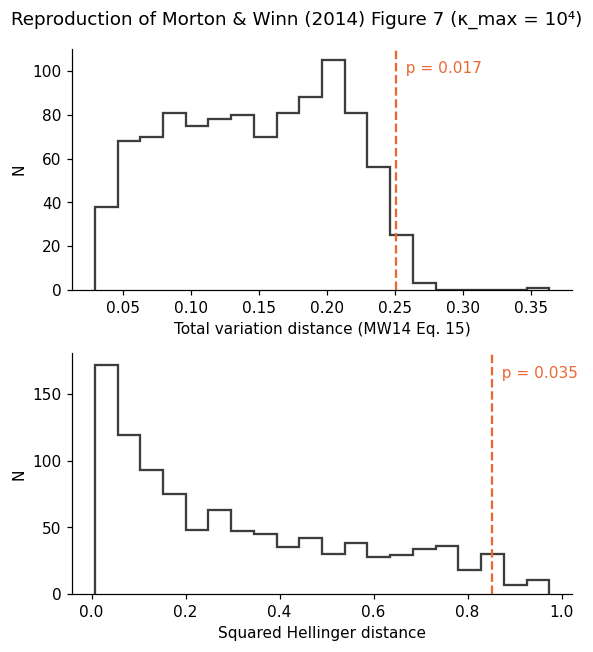

In [19]:
obs, trials, pval = perm[1e4]
fig, axes = plt.subplots(2, 1, figsize=(5.5, 6))
for ax, j, name in [(axes[0], 0, "Total variation distance (MW14 Eq. 15)"),
                    (axes[1], 1, "Squared Hellinger distance")]:
    ax.hist(trials[:, j], bins=20, histtype="step", color="#3d3d3a", lw=1.5)
    ax.axvline(obs[j], ls="--", color=GCOL["multi"])
    ax.text(obs[j], ax.get_ylim()[1] * 0.9, f"  p = {pval[j]:.3f}", color=GCOL["multi"])
    ax.set(xlabel=name, ylabel="N")
fig.suptitle("Reproduction of Morton & Winn (2014) Figure 7 (κ_max = 10⁴)")
fig.tight_layout(); fig.savefig(FIG / "stage1_mw14_fig7.png", bbox_inches="tight")

## 13. The distribution of x = (v sin i − v) / σ

v sin i = v · sin i, so the **true** x is ≤ 0 for every star and reaches 0 only
at i = 90° (consistent with alignment; a misalignment purely in the sky plane
also gives i = 90°). Measured x scatters around the true value by the
measurement errors. Two consequences:

* Cutting stars at measured x > +2σ preferentially removes stars whose true x is
  near 0, i.e. stars consistent with alignment. Such a cut suppresses signal and
  is not a systematics test (Section 15 reports it only for completeness).
* Stars misaligned along the line of sight have true x < 0, so an obliquity spread
  appears as a negative tail of x. With equal measurement errors in both groups,
  √(spread_single² − spread_multi²) estimates the extra astrophysical spread of
  the singles, without any obliquity model.

v = 2πR/P_eq from the same Monte Carlo as L_v (spot-latitude corrected); σ adds
the `v sin i` error and the 16–84% half-width of v in quadrature.

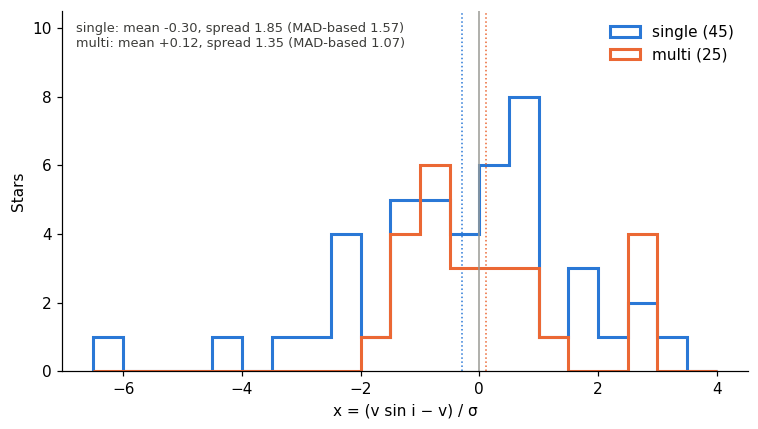

In [20]:
tension = pd.DataFrame([{"koi": int(r.koi), "group": r.group, "vsini": r.vsini, "vsini_err": r.vsini_err,
                         **vsini_excess_sigma(r, np.random.default_rng(int(r.koi)), alpha=0.23,
                                              lat_mean_deg=20, lat_sd_deg=20)}
                        for _, r in df.iterrows()])
tension.to_csv(PROC / "stage1_vsini_excess.csv", index=False)
x = {g: tension.query("group == @g").excess_sigma.values for g in ("single", "multi")}
stat = {g: dict(mean=v.mean(), sd=v.std(ddof=1), sd_mad=1.4826 * np.median(np.abs(v - np.median(v))))
        for g, v in x.items()}

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(-6.5, 4.01, 0.5)
for g, va in (("single", "top"), ("multi", "top")):
    ax.hist(x[g], bins, histtype="step", lw=2, color=GCOL[g], label=f"{g} ({len(x[g])})")
    ax.axvline(stat[g]["mean"], color=GCOL[g], lw=1, ls=":")
ax.axvline(0, color="#9a9a94", lw=1)
txt = "\n".join(f"{g}: mean {stat[g]['mean']:+.2f}, spread {stat[g]['sd']:.2f} (MAD-based {stat[g]['sd_mad']:.2f})"
                for g in ("single", "multi"))
ax.text(0.02, 0.97, txt, transform=ax.transAxes, va="top", fontsize=8.5, color="#3d3d3a")
ax.set(xlabel="x = (v sin i − v) / σ", ylabel="Stars", ylim=(0, 10.5))
ax.legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "stage1_vsini_excess.png", bbox_inches="tight")

In [21]:
from scipy import stats as st
rng = np.random.default_rng(13)
def excess_spread(a, b):
    d = a ** 2 - b ** 2
    return np.sign(d) * np.sqrt(abs(d))
boot = np.array([excess_spread(np.std(rng.choice(x["single"], len(x["single"])), ddof=1),
                               np.std(rng.choice(x["multi"], len(x["multi"])), ddof=1)) for _ in range(5000)])
est = excess_spread(stat["single"]["sd"], stat["multi"]["sd"])
est_mad = excess_spread(stat["single"]["sd_mad"], stat["multi"]["sd_mad"])
print(f"sqrt(spread_single² − spread_multi²) = {est:.2f} σ   "
      f"(bootstrap 68%: {np.percentile(boot, 16):.2f} to {np.percentile(boot, 84):.2f}; "
      f"P(≤ 0) = {np.mean(boot <= 0):.3f})")
print(f"same with MAD-based spreads (robust to the x = −6.2 outlier): {est_mad:.2f} σ")
n_hi = int((tension.excess_sigma > 2).sum())
print(f"\nstars with x > +2σ: {n_hi} of 70. If the errors were right, even with every star at "
      f"i = 90° the expected number is 70 × {st.norm.sf(2):.4f} = {70 * st.norm.sf(2):.1f}; "
      f"binomial P(≥ {n_hi}) = {st.binom.sf(n_hi - 1, 70, st.norm.sf(2)):.1e}")
tension.query("excess_sigma > 2").sort_values("excess_sigma", ascending=False).round(2)

sqrt(spread_single² − spread_multi²) = 1.27 σ   (bootstrap 68%: 0.78 to 1.61; P(≤ 0) = 0.042)
same with MAD-based spreads (robust to the x = −6.2 outlier): 1.15 σ

stars with x > +2σ: 8 of 70. If the errors were right, even with every star at i = 90° the expected number is 70 × 0.0228 = 1.6; binomial P(≥ 8) = 1.9e-04


,koi,group,vsini,vsini_err,v,sigma_v,excess_sigma
40,635,single,8.82,0.52,5.98,0.72,3.18
10,156,multi,2.26,0.50,0.83,0.10,2.81
21,288,single,10.06,0.50,8.26,0.44,2.71
4,85,multi,11.30,0.50,9.41,0.51,2.65
47,896,multi,3.16,0.50,1.79,0.14,2.64
55,1445,multi,17.51,0.50,11.81,2.13,2.61
30,340,single,7.46,0.50,4.90,0.89,2.51
32,345,single,2.37,0.50,1.13,0.08,2.45


The excess at x > +2σ cannot come from obliquities, which only push x negative.
It means the quoted errors are too small, or v is biased low (e.g. by the
spot-latitude prescription), for at least some stars. That motivates the global
error-inflation test below. The spread above is in units of each star's own σ,
so it is a model-free indicator of the singles' extra spread, not an angle.

## 14. Global error-inflation test (MW14 method)

All `v sin i` uncertainties × f, identically for singles and multis,
f ∈ {1.0, 1.15, 1.35}. The upper value comes from the multis' observed x spread
(1.35), which bounds their measurement-only spread from above. Inflating only
σ(v sin i) raises the total σ in x by less than f; the effective factor is shown.

In [22]:
KAPPA_FINE = np.unique(np.concatenate([np.arange(2, 10, 0.01), np.arange(10, 30.0001, 0.05)]))
table_fine = fcosi_table(cache=PROC / "fcosi_table_fine.npz", kappa_grid=KAPPA_FINE)

def ladder_row(run, label, sel=None, perm_seed=4300):
    sel = np.ones(len(df), bool) if sel is None else sel
    ll, llf = run["ll_star"][sel], per_star_log_likelihood(run["samples"][sel], table_fine)
    row = {"run": label, "N single/multi": f"{(groups['single'] & sel).sum()}/{(groups['multi'] & sel).sum()}"}
    for g in ("single", "multi"):
        m = groups[g][sel]
        s = summarize_kappa(kappa_posterior(ll[m].sum(0)))
        row[f"κ_{g} mode"] = KAPPA_FINE[np.argmax(llf[m].sum(0) + log_kappa_prior(KAPPA_FINE))]
        row[f"κ_{g} 68%"] = f"{s['hpd68_lo']:.1f}–{s['hpd68_hi']:.1f}"
    _, _, pv = permutation_test(ll, int(groups["single"][sel].sum()), 1000,
                                np.random.default_rng(perm_seed), groups["single"][sel])
    row["p(TVD)"], row["p(H²)"] = pv
    return row

ladder = {}
rows = []
for f in (1.0, 1.15, 1.35):
    ladder[f] = run_sample(df, table, method=METHOD, vsini_err_scale=f)
    eff = np.median([np.hypot(f * r.vsini_err, t.sigma_v) / np.hypot(r.vsini_err, t.sigma_v)
                     for (_, r), (_, t) in zip(df.iterrows(), tension.iterrows())])
    rows.append({**ladder_row(ladder[f], f"f = {f}"), "median effective σ_x factor": eff})
assert np.array_equal(ladder[1.0]["samples"], samples), "f = 1 run must reproduce Section 6 exactly"
ladder_mw14 = pd.DataFrame(rows)
ladder_mw14.to_csv(PROC / "stage1_error_inflation_mw14.csv", index=False)
ladder_mw14.round(3)

,run,N single/multi,κ_single mode,κ_single 68%,κ_multi mode,κ_multi 68%,p(TVD),p(H²),median effective σ_x factor
0,f = 1.0,45/25,4.73,3.3–6.5,17.20,4.3–160.5,0.017,0.035,1.000
1,f = 1.15,45/25,4.82,3.4–6.7,17.95,4.4–162.7,0.014,0.035,1.093
2,f = 1.35,45/25,4.91,3.4–6.8,18.35,4.5–162.9,0.013,0.037,1.223


## 15. For completeness only: the signal-suppressing x > +2σ cut

Because the cut preferentially removes stars consistent with alignment (Section
13), changes in κ or p under it are expected by construction and are not
evidence about systematics. Reported so the number exists, not interpreted.

In [23]:
keep = (tension.excess_sigma <= 2).values
pd.DataFrame([ladder_row(ladder[1.0], "all 70 (f = 1)"),
              ladder_row(ladder[1.0], f"x ≤ +2σ only ({keep.sum()} stars; signal-suppressing)", keep, 4301)]).round(3)

,run,N single/multi,κ_single mode,κ_single 68%,κ_multi mode,κ_multi 68%,p(TVD),p(H²)
0,all 70 (f = 1),45/25,4.73,3.3–6.5,17.20,4.3–160.5,0.017,0.035
1,x ≤ +2σ only (62 stars; signal-suppressing),41/21,4.07,2.7–5.8,10.85,2.4–88.2,0.052,0.049
